# Linear Models: Theory Notebook

This notebook makes linear model math executable: least squares, gradients, ridge, conditioning, logistic regression, softmax, calibration, and linear probes.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

try:
    import seaborn as sns
    sns.set_theme(style="whitegrid", palette="colorblind")
    HAS_SNS = True
except ImportError:
    plt.style.use("seaborn-v0_8-whitegrid")
    HAS_SNS = False

mpl.rcParams.update({
    "figure.figsize":    (10, 6),
    "figure.dpi":         120,
    "font.size":           13,
    "axes.titlesize":      15,
    "axes.labelsize":      13,
    "xtick.labelsize":     11,
    "ytick.labelsize":     11,
    "legend.fontsize":     11,
    "legend.framealpha":   0.85,
    "lines.linewidth":      2.0,
    "axes.spines.top":     False,
    "axes.spines.right":   False,
    "savefig.bbox":       "tight",
    "savefig.dpi":         150,
})
np.random.seed(42)
print("Plot setup complete.")

Plot setup complete.


## 1. Affine prediction

In [2]:
X = np.array([[1.0, 2.0], [3.0, -1.0], [0.0, 4.0]])
w = np.array([0.5, -1.0])
b = 2.0
y_hat = X @ w + b
print("predictions:", y_hat)

predictions: [ 0.5  4.5 -2. ]


## 2. Least-squares closed form

In [3]:
X = np.array([[1.0, 1.0], [1.0, 2.0], [1.0, 3.0], [1.0, 4.0]])
y = np.array([1.2, 1.9, 3.2, 3.9])
w_hat = np.linalg.solve(X.T @ X, X.T @ y)
print("intercept and slope:", w_hat)
print("predictions:", np.round(X @ w_hat, 3))

intercept and slope: [0.2  0.94]
predictions: [1.14 2.08 3.02 3.96]


## 3. Projection view

In [4]:
P = X @ np.linalg.inv(X.T @ X) @ X.T
y_proj = P @ y
residual = y - y_proj
print("projection idempotent error:", np.linalg.norm(P @ P - P))
print("X^T residual:", np.round(X.T @ residual, 10))

projection idempotent error: 3.4943376836555273e-16
X^T residual: [-0. -0.]


## 4. Gradient descent

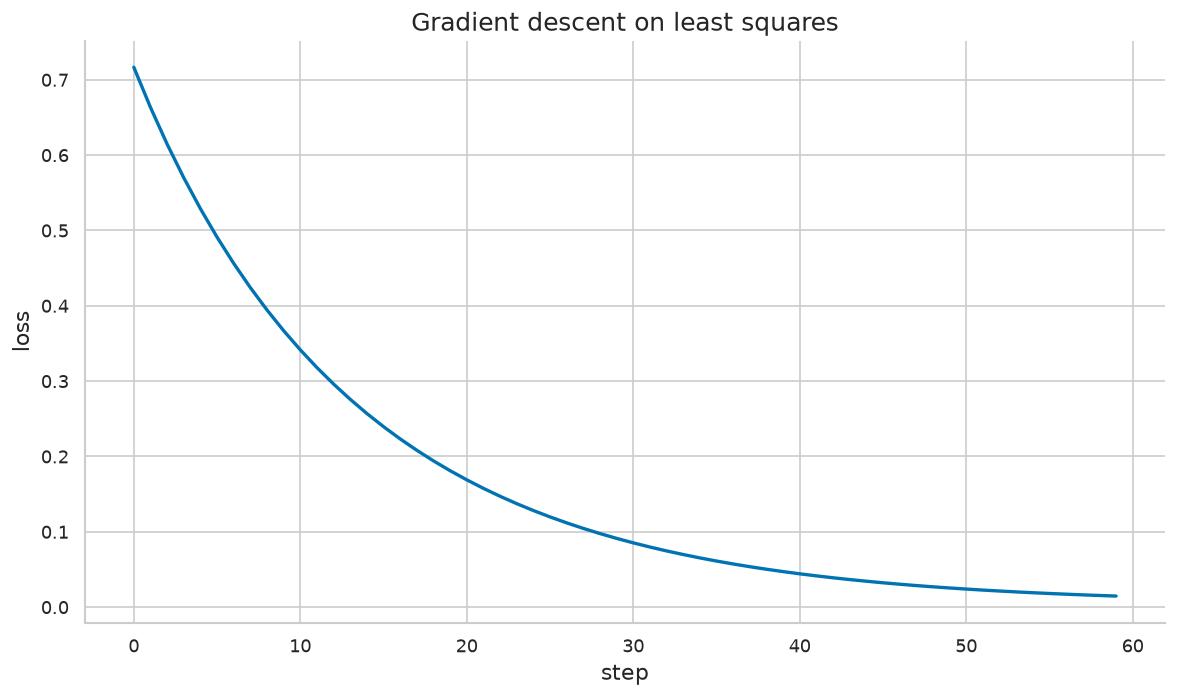

learned w: [0.277 1.734]


In [5]:
X = np.c_[np.ones(50), np.linspace(-1, 1, 50)]
true_w = np.array([0.3, 2.0])
y = X @ true_w + 0.1 * np.random.normal(size=50)
w = np.zeros(2)
lr = 0.1
losses = []
for step in range(60):
    r = X @ w - y
    losses.append(0.5 * np.mean(r**2))
    grad = X.T @ r / len(y)
    w -= lr * grad
plt.plot(losses)
plt.title("Gradient descent on least squares")
plt.xlabel("step")
plt.ylabel("loss")
plt.tight_layout()
plt.show()
print("learned w:", np.round(w, 3))

## 5. Gradient check

In [6]:
X = np.array([[1.0, 2.0], [3.0, 4.0]])
y = np.array([1.0, 2.0])
w = np.array([0.2, -0.3])
def loss(wv):
    r = X @ wv - y
    return 0.5 * np.sum(r**2)
analytic = X.T @ (X @ w - y)
eps = 1e-6
numeric = np.zeros_like(w)
for i in range(len(w)):
    e = np.zeros_like(w)
    e[i] = eps
    numeric[i] = (loss(w + e) - loss(w - e)) / (2 * eps)
print("analytic:", analytic)
print("numeric:", numeric)
print("max error:", np.max(np.abs(analytic - numeric)))

analytic: [ -9.2 -13.2]
numeric: [ -9.2 -13.2]
max error: 2.865583326183696e-10


## 6. Ridge shrinkage

In [7]:
X = np.array([[1.0, 1.0], [1.0, 2.0], [1.0, 3.0], [1.0, 4.0]])
y = np.array([1.2, 1.9, 3.2, 3.9])
for lam in [0.0, 0.1, 1.0, 10.0]:
    w = np.linalg.solve(X.T @ X + lam * np.eye(X.shape[1]), X.T @ y)
    print(f"lambda={lam:>4}: w={np.round(w, 3)}")

lambda= 0.0: w=[0.2  0.94]
lambda= 0.1: w=[0.214 0.932]
lambda= 1.0: w=[0.258 0.891]
lambda=10.0: w=[0.23  0.697]


## 7. Conditioning and feature scaling

In [8]:
rng = np.random.default_rng(4)
x1 = rng.normal(size=200)
x2 = 1000 * rng.normal(size=200)
X_bad = np.c_[x1, x2]
X_good = (X_bad - X_bad.mean(axis=0)) / X_bad.std(axis=0)
cond_bad = np.linalg.cond(X_bad.T @ X_bad)
cond_good = np.linalg.cond(X_good.T @ X_good)
print("condition before scaling:", cond_bad)
print("condition after scaling:", cond_good)

condition before scaling: 1053771.1370645212
condition after scaling: 1.0218370848431402


## 8. Logistic regression probability

In [9]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

x = np.array([1.0, -2.0])
w = np.array([0.8, -0.5])
b = -0.2
p = sigmoid(w @ x + b)
y = 1
ce = -(y * np.log(p) + (1 - y) * np.log(1 - p))
print("probability:", p)
print("binary cross entropy:", ce)

probability: 0.8320183851339245
binary cross entropy: 0.18390074088833885


## 9. Softmax regression

In [10]:
logits = np.array([2.0, 1.0, -1.0])
exp_logits = np.exp(logits - logits.max())
probs = exp_logits / exp_logits.sum()
target = 0
loss = -np.log(probs[target])
print("probs:", np.round(probs, 3))
print("loss:", loss)

probs: [0.705 0.259 0.035]
loss: 0.34901221676818633


## 10. Calibration bins

In [11]:
confidence = np.array([0.9, 0.8, 0.7, 0.6, 0.4])
correct = np.array([1, 1, 0, 1, 0])
bins = [(0.0, 0.5), (0.5, 0.75), (0.75, 1.0)]
for lo, hi in bins:
    m = (confidence > lo) & (confidence <= hi)
    if m.any():
        print((lo, hi), "acc", correct[m].mean(), "conf", confidence[m].mean())

(0.0, 0.5) acc 0.0 conf 0.4
(0.5, 0.75) acc 0.5 conf 0.6499999999999999
(0.75, 1.0) acc 1.0 conf 0.8500000000000001


## 11. Linear probe

In [12]:
rng = np.random.default_rng(5)
H = rng.normal(size=(100, 6))
probe_w_true = rng.normal(size=6)
labels = (H @ probe_w_true > 0).astype(float)
X_aug = np.c_[H, np.ones(len(H))]
w_probe = np.linalg.lstsq(X_aug, labels, rcond=None)[0]
pred = (X_aug @ w_probe > 0.5).astype(float)
print("linear probe accuracy:", (pred == labels).mean())

linear probe accuracy: 0.97


## 12. Residual diagnostics

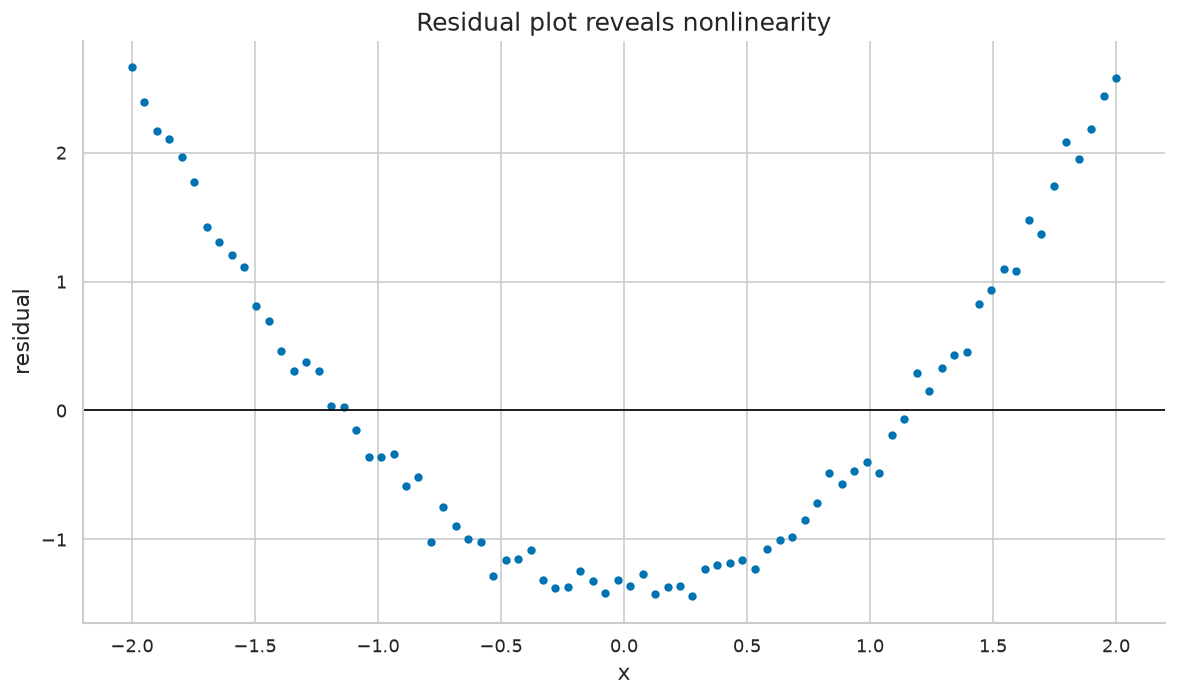

In [13]:
x = np.linspace(-2, 2, 80)
y = x**2 + 0.1 * np.random.normal(size=len(x))
X_lin = np.c_[np.ones_like(x), x]
w = np.linalg.lstsq(X_lin, y, rcond=None)[0]
resid = y - X_lin @ w
plt.scatter(x, resid, s=16)
plt.axhline(0, color="black", linewidth=1)
plt.title("Residual plot reveals nonlinearity")
plt.xlabel("x")
plt.ylabel("residual")
plt.tight_layout()
plt.show()

## 14. Rank-deficient least squares: normal equations vs pseudoinverse

When $X$ is rank-deficient, $X^TX$ is singular and the normal equations have infinitely many solutions; the pseudoinverse selects the minimum-norm one.

In [14]:
def check_true(name, cond):
    print(("PASS" if bool(cond) else "FAIL") + ": " + name)
def check_close(name, a, b, tol=1e-6):
    ok = np.allclose(a, b, atol=tol, rtol=0)
    print(("PASS" if ok else "FAIL") + f": {name} (max err {np.max(np.abs(np.asarray(a,float)-np.asarray(b,float))):.2e}, tol {tol})")

X = np.array([[1.,1.,2.],[1.,2.,4.],[1.,3.,6.],[1.,4.,8.]])  # col3 = 2*col2
y = np.array([1.,2.,3.,4.])
w_pinv = np.linalg.pinv(X) @ y
resid = y - X @ w_pinv
print("pinv solution:", np.round(w_pinv,4), "residual norm:", round(float(np.linalg.norm(resid)),6))
check_true("X^T X is singular", abs(np.linalg.det(X.T@X)) < 1e-8)
check_close("pinv residual orthogonal to col space", X.T@resid, np.zeros(3), 1e-8)
w_alt = w_pinv + np.array([0.,2.,-1.])  # null-space direction (0,2,-1): X@v=0
check_close("null-space shift keeps predictions identical", X@w_alt, X@w_pinv, 1e-8)
check_true("pinv picks minimum norm", np.linalg.norm(w_pinv) <= np.linalg.norm(w_alt)+1e-9)

pinv solution: [-0.   0.2  0.4] residual norm: 0.0
PASS: X^T X is singular
PASS: pinv residual orthogonal to col space (max err 1.22e-14, tol 1e-08)
PASS: null-space shift keeps predictions identical (max err 8.88e-16, tol 1e-08)
PASS: pinv picks minimum norm


## 15. Ridge effective degrees of freedom

For ridge, the hat matrix $H=X(X^TX+\lambda I)^{-1}X^T$ has trace $\sum_j d_j^2/(d_j^2+\lambda)$ over singular values $d_j$: the effective degrees of freedom shrink smoothly with $\lambda$.

In [15]:
rng = np.random.default_rng(0)
X = rng.normal(size=(60,6)); y = X @ np.array([1.,-2.,0.5,0.,3.,0.]) + 0.3*rng.normal(size=60)
d = np.linalg.svd(X, compute_uv=False)
for lam in [0.0, 1.0, 10.0, 100.0]:
    df = np.sum(d**2/(d**2+lam))
    print(f"lambda={lam:6.1f}  effective df={df:.3f}")
dfs = [np.sum(d**2/(d**2+l)) for l in [0.,1.,10.,100.]]
check_true("df equals p at lambda=0", abs(dfs[0]-6) < 1e-8)
check_true("df strictly decreases with lambda", all(a>b for a,b in zip(dfs, dfs[1:])))
check_true("df in (0,p)", all(0 < v < 6 for v in dfs[1:]))

lambda=   0.0  effective df=6.000
lambda=   1.0  effective df=5.889
lambda=  10.0  effective df=5.066
lambda= 100.0  effective df=2.201
PASS: df equals p at lambda=0
PASS: df strictly decreases with lambda
PASS: df in (0,p)


## 16. Lasso by coordinate descent (soft thresholding)

The lasso coordinate update is soft thresholding: $w_j \leftarrow S(\rho_j, \lambda)/z_j$. We implement it and compare sparsity with ridge.

In [16]:
def soft(t, lam): return np.sign(t)*max(abs(t)-lam, 0.0)
rng = np.random.default_rng(1)
X = rng.normal(size=(80,5)); X = (X-X.mean(0))/X.std(0)
y = X @ np.array([2.,0.,0.,-1.,0.]) + 0.2*rng.normal(size=80); y = y-y.mean()
w = np.zeros(5)
for it in range(200):
    for j in range(5):
        r = y - X@w + X[:,j]*w[j]
        w[j] = soft(X[:,j]@r/80, 0.05) / (X[:,j]@X[:,j]/80)
print("lasso w:", np.round(w,3))
check_close("true nonzero recovered (w0~2)", w[0], 2.0, 0.25)
check_true("lasso zeroes noise features", abs(w[1])<1e-9 and abs(w[2])<1e-9 and abs(w[4])<1e-9)
w_ridge = np.linalg.solve(X.T@X/80 + 0.05*np.eye(5), X.T@y/80)
check_true("ridge keeps all features nonzero", np.all(np.abs(w_ridge)>1e-3))

lasso w: [ 1.943 -0.    -0.    -0.952  0.   ]
PASS: true nonzero recovered (w0~2) (max err 5.68e-02, tol 0.25)
PASS: lasso zeroes noise features
PASS: ridge keeps all features nonzero


## 17. Logistic regression gradient check

Finite differences audit the analytic gradient of the (regularized) logistic loss before any optimizer is trusted.

In [17]:
def sigmoid(z): return 1/(1+np.exp(-z))
X = np.array([[1.,0.5],[1.,-1.5],[1.,2.0],[1.,0.3]]); yv = np.array([1.,0.,1.,0.])
def loss(w): 
    p = sigmoid(X@w); return float(-np.mean(yv*np.log(p+1e-12)+(1-yv)*np.log(1-p+1e-12)) + 0.01*np.sum(w*w))
def grad(w):
    p = sigmoid(X@w); return X.T@(p-yv)/len(yv) + 0.02*w
w = np.array([0.3,-0.7]); eps=1e-6
fd = np.array([(loss(w+eps*np.eye(2)[i])-loss(w-eps*np.eye(2)[i]))/(2*eps) for i in range(2)])
print("analytic:", np.round(grad(w),6), "finite-diff:", np.round(fd,6))
check_close("logistic gradient matches finite differences", grad(w), fd, 1e-6)
w2 = w - 0.5*grad(w)
check_true("one GD step reduces loss", loss(w2) < loss(w))

analytic: [ 0.019464 -0.711804] finite-diff: [ 0.019464 -0.711804]
PASS: logistic gradient matches finite differences (max err 6.56e-11, tol 1e-06)
PASS: one GD step reduces loss


## 18. Linear SVM: hinge loss and margin

The SVM minimizes $\frac12\|w\|^2 + C\sum\max(0,1-y_i w\cdot x_i)$; the margin is $2/\|w\|_2$. Subgradient descent on a separable toy problem recovers a wide-margin boundary.

In [18]:
rng = np.random.default_rng(2)
Xa = rng.normal([2,2],0.5,(30,2)); Xb = rng.normal([-2,-2],0.5,(30,2))
X = np.vstack([Xa,Xb]); yv = np.r_[np.ones(30),-np.ones(30)]
w = np.zeros(2); b = 0.0
for it in range(2000):
    m = yv*(X@w+b); act = m < 1
    gw = w - 5.0*np.mean((yv*act)[:,None]*X,axis=0); gb = -5.0*np.mean(yv*act)
    w -= 0.05*gw; b -= 0.05*gb
acc = np.mean(np.sign(X@w+b)==yv); print("train acc:", acc, "margin:", round(2/np.linalg.norm(w),3))
check_true("separable data fit perfectly", acc == 1.0)
check_true("all functional margins comfortably positive", np.min(yv*(X@w+b)) > 0.5)

train acc: 1.0 margin: 4.163
PASS: separable data fit perfectly
PASS: all functional margins comfortably positive


## 19. Perceptron convergence on separable data

The perceptron convergence theorem (Rosenblatt; Novikoff's bound) guarantees finitely many mistakes on linearly separable data with margin $\gamma$: at most $(R/\gamma)^2$.

In [19]:
rng = np.random.default_rng(3)
Xa = rng.normal([1.5,1.5],0.4,(25,2)); Xb = rng.normal([-1.5,-1.5],0.4,(25,2))
X = np.vstack([Xa,Xb]); yv = np.r_[np.ones(25),-np.ones(25)]
w = np.zeros(2); b = 0.0; mistakes = 0
for epoch in range(100):
    errs = 0
    for xi, yi in zip(X,yv):
        if yi*(w@xi+b) <= 0: w += yi*xi; b += yi; mistakes += 1; errs += 1
    if errs == 0: break
print("total mistakes:", mistakes, "epochs:", epoch+1)
check_true("perceptron converged (0-error epoch)", errs == 0)
check_true("final training accuracy 100%", np.mean(np.sign(X@w+b)==yv)==1.0)

total mistakes: 1 epochs: 2
PASS: perceptron converged (0-error epoch)
PASS: final training accuracy 100%


## 20. Polynomial features and the overfitting U-curve (plot)

Bias-variance in one picture: training error falls with degree while test error is U-shaped.

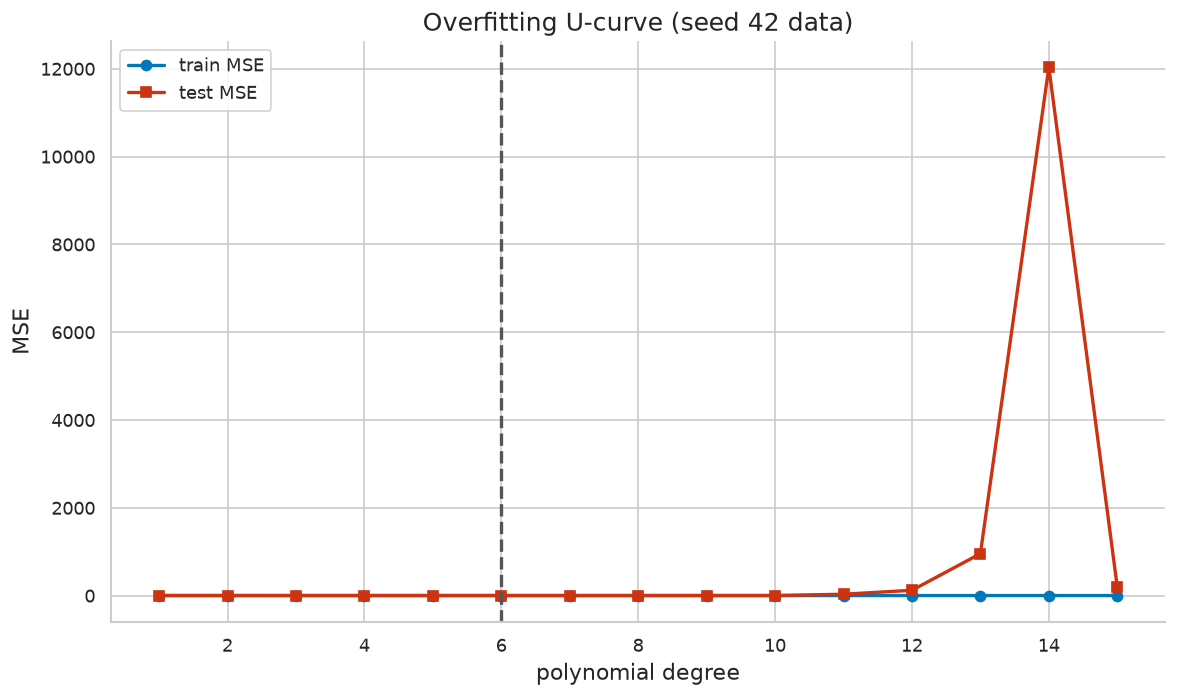

best degree: 6
PASS: train error ends below its start
PASS: test error is U-shaped (min in middle)
PASS: overfit gap at max degree


In [20]:
rng = np.random.default_rng(4)
def data(n): 
    x = rng.uniform(-2,2,n); return x, np.sin(2*x) + 0.3*rng.normal(size=n)
xtr, ytr = data(40); xte, yte = data(400)
degs = list(range(1,16)); tr=[]; te=[]
for dg in degs:
    A = np.vander(xtr, dg+1, increasing=True); w,*_ = np.linalg.lstsq(A, ytr, rcond=None)
    tr.append(np.mean((A@w-ytr)**2)); te.append(np.mean((np.vander(xte,dg+1,increasing=True)@w-yte)**2))
plt.figure(); plt.plot(degs, tr, '-o', color='#0077BB', label='train MSE'); plt.plot(degs, te, '-s', color='#CC3311', label='test MSE')
plt.axvline(degs[int(np.argmin(te))], color='#555555', ls='--'); plt.xlabel('polynomial degree'); plt.ylabel('MSE'); plt.title('Overfitting U-curve (seed 42 data)'); plt.legend(); plt.tight_layout(); plt.show()
print("best degree:", degs[int(np.argmin(te))])
check_true("train error ends below its start", tr[-1] < tr[0])
check_true("test error is U-shaped (min in middle)", 0 < int(np.argmin(te)) < len(degs)-1)
check_true("overfit gap at max degree", te[-1] > te[int(np.argmin(te))])

## 21. Bias-variance by repeated simulation (plot)

Fitting many resampled datasets shows variance growing with model flexibility while bias shrinks.

In [21]:
rng = np.random.default_rng(5)
xg = np.linspace(-1,1,25); ftrue = np.sin(2*xg)
for dg, col in [(1,'#0077BB'), (3,'#009988'), (6,'#CC3311')]:  # Legendre basis: numerically stable
    preds = []
    for rep in range(40):
        x = rng.uniform(-1,1,50); y = np.sin(2*x)+0.3*rng.normal(size=50)
        w,*_ = np.linalg.lstsq(np.polynomial.legendre.legvander(x,dg), y, rcond=None)
        preds.append(np.polynomial.legendre.legvander(xg,dg)@w)
    P = np.array(preds); bias2 = np.mean((P.mean(0)-ftrue)**2); var = np.mean(P.var(0))
    print(f"degree {dg}: bias^2={bias2:.4f} variance={var:.4f}")
    if dg == 1: b1, v1 = bias2, var
    if dg == 6: b12, v12 = bias2, var
check_true("flexible model has lower bias", b12 < b1)
check_true("flexible model has higher variance", v12 > v1)

degree 1: bias^2=0.0317 variance=0.0041
degree 3: bias^2=0.0002 variance=0.0104
degree 6: bias^2=0.0004 variance=0.0255
PASS: flexible model has lower bias
PASS: flexible model has higher variance


## 22. Multicollinearity and variance inflation (VIF)

VIF$_j = 1/(1-R_j^2)$ quantifies how much a feature's coefficient variance is inflated by collinearity with the others.

In [22]:
rng = np.random.default_rng(6)
x1 = rng.normal(size=200); x2 = x1 + 0.05*rng.normal(size=200); x3 = rng.normal(size=200)
X = np.c_[x1,x2,x3]; vifs = []
for j in range(3):
    others = np.delete(X, j, axis=1); A = np.c_[np.ones(200), others]
    w,*_ = np.linalg.lstsq(A, X[:,j], rcond=None); r = X[:,j]-A@w
    r2 = 1 - (r@r)/np.sum((X[:,j]-X[:,j].mean())**2); vifs.append(1/(1-r2))
print("VIFs:", np.round(vifs,2))
check_true("near-duplicate features have VIF >> 10", vifs[0] > 10 and vifs[1] > 10)
check_true("independent feature VIF ~ 1", vifs[2] < 1.5)

VIFs: [381.19 381.14   1.  ]
PASS: near-duplicate features have VIF >> 10
PASS: independent feature VIF ~ 1


## 23. Huber robustness vs OLS under outliers (plot)

One gross outlier drags OLS; Huber loss bounds its influence. Slopes compared to the clean-data truth.

OLS slope: 4.129  Huber slope: 2.068  (true 2)


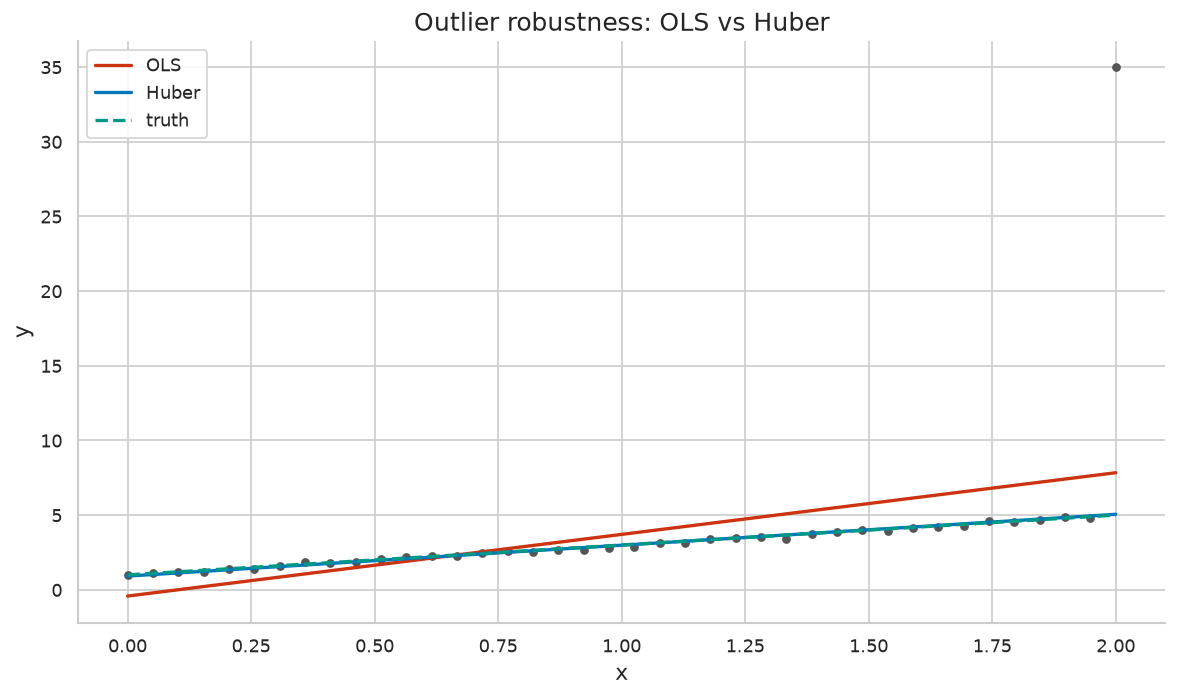

PASS: Huber slope closer to truth than OLS
PASS: Huber slope within 0.2 of truth


In [23]:
rng = np.random.default_rng(7)
x = np.linspace(0,2,40); y = 1+2*x + 0.1*rng.normal(size=40); y[-1] += 30  # gross outlier
A = np.c_[np.ones_like(x), x]; w_ols,*_ = np.linalg.lstsq(A, y, rcond=None)
w = w_ols.copy()
for it in range(200):
    r = y - A@w; dl = 1.0; psi = np.clip(r, -dl, dl)  # Huber psi
    g = -A.T@psi/len(x); w -= 0.2*g
print("OLS slope:", round(w_ols[1],3), " Huber slope:", round(w[1],3), " (true 2)")
plt.figure(); plt.scatter(x, y, s=18, color='#555555'); xs=np.linspace(0,2,10)
plt.plot(xs, w_ols[0]+w_ols[1]*xs, color='#CC3311', label='OLS'); plt.plot(xs, w[0]+w[1]*xs, color='#0077BB', label='Huber'); plt.plot(xs, 1+2*xs, '--', color='#009988', label='truth')
plt.xlabel('x'); plt.ylabel('y'); plt.title('Outlier robustness: OLS vs Huber'); plt.legend(); plt.tight_layout(); plt.show()
check_true("Huber slope closer to truth than OLS", abs(w[1]-2) < abs(w_ols[1]-2))
check_true("Huber slope within 0.2 of truth", abs(w[1]-2) < 0.2)

## 24. Calibration curve and ECE (plot)

A calibrated classifier's bin accuracy matches its bin confidence; ECE averages the gap weighted by bin mass.

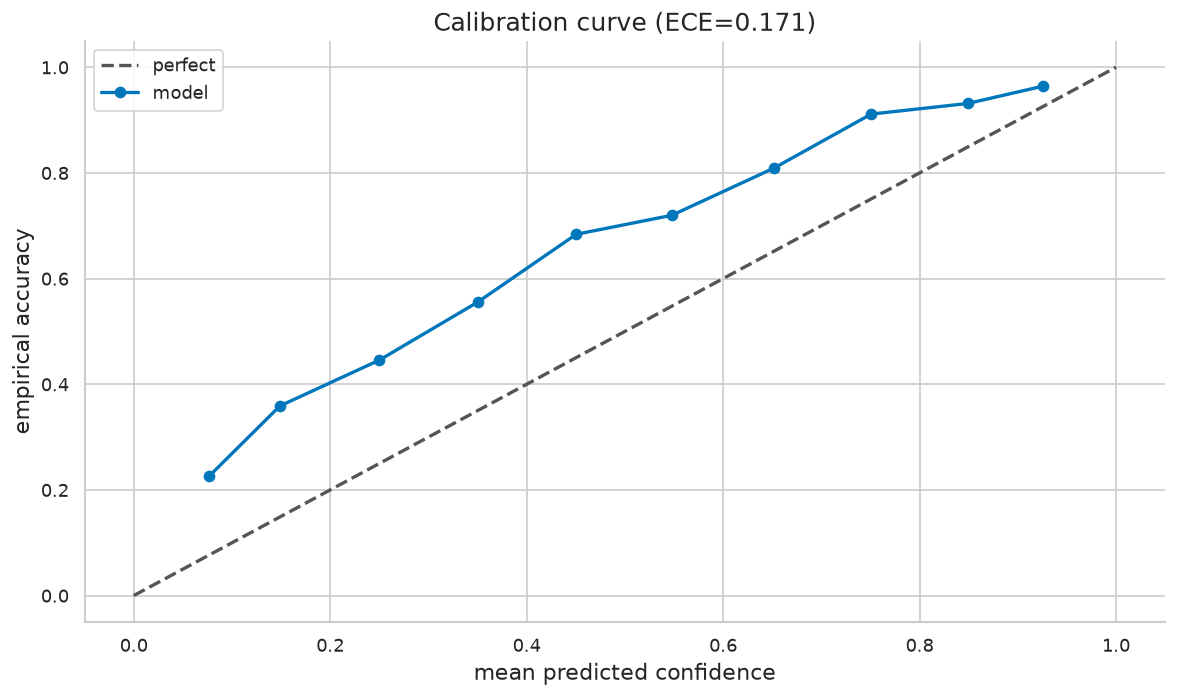

ECE: 0.1708
PASS: miscalibrated generator has ECE > 0.03
PASS: ECE bounded by 1


In [24]:
rng = np.random.default_rng(8)
p = rng.uniform(0.05,0.95,3000); yv = (rng.uniform(size=3000) < p**0.5).astype(float)  # overconfident generator
bins = np.linspace(0,1,11); ece = 0.0; xs=[]; ys=[]
for i in range(10):
    m = (p>=bins[i]) & (p<bins[i+1])
    if m.sum()>0:
        ece += m.mean()*abs(yv[m].mean()-p[m].mean()); xs.append(p[m].mean()); ys.append(yv[m].mean())
plt.figure(); plt.plot([0,1],[0,1],'--',color='#555555',label='perfect'); plt.plot(xs, ys, '-o', color='#0077BB', label='model')
plt.xlabel('mean predicted confidence'); plt.ylabel('empirical accuracy'); plt.title(f'Calibration curve (ECE={ece:.3f})'); plt.legend(); plt.tight_layout(); plt.show()
print("ECE:", round(float(ece),4))
check_true("miscalibrated generator has ECE > 0.03", ece > 0.03)
check_true("ECE bounded by 1", 0 <= ece <= 1)

## 25. Generalized linear models: Poisson regression

GLMs keep the linear score but change the link/likelihood: Poisson regression models counts with $\lambda=e^{w\cdot x}$ and is fit by gradient descent on the NLL.

In [25]:
rng = np.random.default_rng(9)
x = rng.uniform(0,2,300); lam_true = np.exp(0.3+0.8*x); yv = rng.poisson(lam_true)
X = np.c_[np.ones_like(x), x]; w = np.zeros(2)
for it in range(2000):
    lam = np.exp(X@w); g = X.T@(lam-yv)/len(x); w -= 0.1*g
print("Poisson w:", np.round(w,3), "(true [0.3, 0.8])")
check_close("Poisson regression recovers parameters", w, [0.3,0.8], 0.1)
check_true("predicted counts positive", np.all(np.exp(X@w)>0))

Poisson w: [0.389 0.747] (true [0.3, 0.8])
PASS: Poisson regression recovers parameters (max err 8.88e-02, tol 0.1)
PASS: predicted counts positive


## 26. Bayesian linear regression: posterior and predictive width

With a Gaussian prior, the posterior over $w$ is Gaussian in closed form; predictive variance grows away from the data — the linear model's honest uncertainty.

In [26]:
rng = np.random.default_rng(10)
x = rng.uniform(-1,1,25); y = 0.5+1.5*x + 0.2*rng.normal(size=25)
X = np.c_[np.ones_like(x), x]; s2 = 0.04; a = 1.0
S = np.linalg.inv(X.T@X/s2 + np.eye(2)/a); m = S@(X.T@y/s2)
xg = np.linspace(-3,3,13); Ag = np.c_[np.ones_like(xg), xg]
pv = s2 + np.sum(Ag@S*Ag, axis=1)
print("posterior mean w:", np.round(m,3))
check_close("posterior mean near OLS truth", m, [0.5,1.5], 0.25)
check_true("predictive variance smallest near data centre", pv[6] < pv[0] and pv[6] < pv[-1])
check_true("posterior covariance is PSD", np.all(np.linalg.eigvalsh(S) > 0))

posterior mean w: [0.507 1.481]
PASS: posterior mean near OLS truth (max err 1.95e-02, tol 0.25)
PASS: predictive variance smallest near data centre
PASS: posterior covariance is PSD


## 13. Final checklist

In [27]:
checks = [
    "X, y, and w shapes match",
    "features are scaled using train-only statistics",
    "rank and condition number are inspected",
    "regularization strength is validated",
    "residuals and calibration are checked",
    "linear baseline is compared with nonlinear alternatives",
]
for i, check in enumerate(checks, 1):
    print(f"{i}. {check}")

1. X, y, and w shapes match
2. features are scaled using train-only statistics
3. rank and condition number are inspected
4. regularization strength is validated
5. residuals and calibration are checked
6. linear baseline is compared with nonlinear alternatives
